In [1]:
import pandas as pd

input_file_traj = "../input/em_trajectories.csv"
input_file_prices = "../input/prices.csv"

bat = "f2fa4e93-8507-42c1-b44d-576242a9f453"
evcs = "ef96659d-8317-4d5e-bec5-ac65a0628535"
pv = "294640d2-6fcf-4d96-a9e9-e988cba7c8cd"
load = "f368082d-1ede-4472-a71c-f2fadfaaa713"
# associated ev: 2bb84106-4144-4c0a-8b4a-bf5d02124d5c

opt_resolution = 3600
sim_resolution = 900
horizon = 86400

In [ ]:
def create_table_cumulative(df: pd.DataFrame, uuid: str) -> pd.DataFrame:
    df_cum = df[(df.asset_uuid == uuid) & (df.tick == df.current_tick + opt_resolution)].reset_index()
    df_cum = df_cum[["asset_uuid", "current_tick", "state", "e_min", "e_max"]]
    # add simulation resolution, since the cumulative sum below determines state at the end of each step
    df_cum.loc[:, "current_tick"] += sim_resolution
    df_cum.loc[:, ["state", "e_min", "e_max"]] *= sim_resolution/opt_resolution
    df_cum.loc[:, ["state", "e_min", "e_max"]] = df_cum.loc[:, ["state", "e_min", "e_max"]].cumsum()

    df_cum.index += 1
    df_cum.loc[0] = { "asset_uuid": uuid, "current_tick": 0, "state": 0.0, "e_min": 0.0, "e_max": 0.0 }
    df_cum.sort_index(inplace=True)

    # skip row because we added sim_resolution to last entry above
    return df_cum[:-1]

def create_table_absolute(df: pd.DataFrame, uuid: str) -> pd.DataFrame:
    last_tick: int = df.current_tick.max()

    df_abs = df[(df.asset_uuid == uuid) & (df.tick == df.current_tick)]
    df_abs = df_abs[["asset_uuid", "current_tick", "state", "e_min", "e_max"]]

    # add missing values, if present
    fill_value = {"asset_uuid": uuid, "state": 0.0, "e_min": 0.0, "e_max": 0.0}
    new_index = pd.Index(range(0,last_tick+1,sim_resolution), name="current_tick")
    df_abs = df_abs.set_index("current_tick").reindex(new_index).reset_index().fillna(fill_value)

    return df_abs

In [ ]:
def adapt_stateless_trajectories(df: pd.DataFrame, uuids: list[str]) -> pd.DataFrame:
    df = df.copy()
    for adapt_uuid in uuids:
        current_ticks = df.current_tick.unique()

        last_diff = 0
        for current_tick in current_ticks:
            selection = (df.asset_uuid == adapt_uuid) & (df.current_tick == current_tick)
            df.loc[selection, "state"] += last_diff
            df.loc[selection, "e_min"] += last_diff
            df.loc[selection, "e_max"] += last_diff
            df.loc[selection, "tight_e_min"] += last_diff
            df.loc[selection, "tight_e_max"] += last_diff

            last_diff += (df[selection]["state"].iloc[1] - df[selection]["state"].iloc[0]) * sim_resolution/opt_resolution

    return df

In [ ]:
def fill_disconnected(df: pd.DataFrame, uuids: list[str], fill_value):
    for adapt_uuid in uuids:
        current_ticks = df.current_tick.unique()

        add_rows = []
        for current_tick in current_ticks:
            selection = (df.asset_uuid == adapt_uuid) & (df.current_tick == current_tick)
            last_tick = df[selection]["tick"].max()

            # add filler values for missing ticks right after the last value
            if last_tick < current_tick + horizon:
                add_rows.append({"asset_uuid": adapt_uuid, "current_tick": current_tick, "tick": last_tick + opt_resolution, "state": fill_value, "e_min": fill_value, "e_max": fill_value, "tight_e_min": fill_value, "tight_e_max": fill_value})

        df = pd.concat([df, pd.DataFrame(add_rows)])

    return df

In [41]:
def create_stacked(traj_bounds: pd.DataFrame, traj_bounds_sum: pd.DataFrame, order: list[str]) -> pd.DataFrame:
    stacked_bounds = traj_bounds_sum[["current_tick", "state"]].copy()

    last_down = traj_bounds_sum["state"]
    last_up = traj_bounds_sum["state"]

    for i in range(0, len(order)):
        asset_borders = traj_bounds[traj_bounds.asset_uuid == order[i]]

        stacked_bounds.loc[:, "down_" + str(i)] = last_down - (asset_borders["state"] - asset_borders["e_min"])
        stacked_bounds.loc[:, "up_" + str(i)] = last_up + asset_borders["e_max"] - asset_borders["state"]

        last_down = stacked_bounds["down_" + str(i)]
        last_up = stacked_bounds["up_" + str(i)]

    return stacked_bounds

In [42]:
# load and prepare data

# TRAJECTORIES
traj_csv = pd.read_csv(input_file_traj)

# remove entries for last tick, because simona sets them to 0
max_tick = traj_csv.current_tick.max()
traj_csv.drop(traj_csv.index[traj_csv.current_tick == max_tick], inplace=True)

# adapt stateless trajectories (because they start at 0 at every simulated tick)
traj_full = adapt_stateless_trajectories(traj_csv, [pv, load])

# fill in disconnected ticks with 0
traj_full = fill_disconnected(traj_full, [evcs], 0.0) # optional: float('nan')

# realized state trajectory and boundaries
traj_real = pd.concat([
    create_table_cumulative(traj_csv, pv),
    create_table_cumulative(traj_csv, load),
    create_table_absolute(traj_csv, bat),
    create_table_absolute(traj_csv, evcs)
    ])

# sum across devices
traj_full_sum = traj_full.groupby(["current_tick", "tick"], as_index=False)[["state", "e_min", "e_max", "tight_e_min", "tight_e_max"]].sum()
traj_real_sum = traj_real.groupby("current_tick", as_index=False)[["state", "e_min", "e_max"]].sum()

# values for stacked representation
traj_real_stacked = create_stacked(traj_real, traj_real_sum, [load, bat, evcs, pv])

# PRICES
prices = pd.read_csv(input_file_prices)
prices['time'] = pd.to_datetime(prices['time'], format='%Y-%m-%dT%H:%M:%SZ')

prices['time'] = (prices['time'] - prices.loc[0, 'time']).map(lambda s: s.total_seconds())

In [35]:
import matplotlib.pyplot as plt

def plot_trajectories(traj: pd.DataFrame, traj_borders: pd.DataFrame):
    plt.subplots(figsize=(20, 6))
    plt.xticks(range(0, 72*3600+1, 3600*4))
    plt.xlim(0, 48*3600)

    curr_ticks = traj.current_tick.unique()
    for curr_tick in curr_ticks:
        state_tick = traj[traj.current_tick == curr_tick]

        plt.plot(state_tick["tick"], state_tick["tight_e_min"], c="#b8b6fc66")
        plt.plot(state_tick["tick"], state_tick["tight_e_max"], c="#00800466")

        plt.plot(state_tick["tick"], state_tick["state"], c="black")

    plt.plot(traj_borders["current_tick"], traj_borders["e_min"], c="#b8b6fc55")
    plt.plot(traj_borders["current_tick"], traj_borders["e_max"], c="#b8b6fc55")
    plt.fill_between(traj_borders["current_tick"], traj_borders["e_min"], traj_borders["e_max"], color="#b8b6fc44")
    plt.plot(traj_borders["current_tick"], traj_borders["state"], c="red")

    plt.show()

def plot_stacked(traj_borders_stacked: pd.DataFrame, num: int):
    plt.subplots(figsize=(20, 6))
    plt.xticks(range(0, 72*3600+1, 3600*4))
    plt.xlim(0, 48*3600)

    colors = ["red", "green", "blue", "yellow"]

    last_up = traj_borders_stacked["state"]
    last_down = traj_borders_stacked["state"]
    for i in range(0, num):
        color = colors[i]

        flex_up = traj_real_stacked["up_" + str(i)]
        flex_down = traj_real_stacked["down_" + str(i)]

        plt.fill_between(traj_real_stacked["current_tick"], last_up, flex_up, color=color)
        plt.fill_between(traj_real_stacked["current_tick"], flex_down, last_down, color=color)

        last_up = flex_up
        last_down = flex_down

    plt.plot(traj_borders_stacked["current_tick"], traj_borders_stacked["state"], c="red")

    plt.show()

def plot_prices(prices):
    plt.subplots(figsize=(20, 6))

    plt.xticks(range(0, 72*3600+1, 3600*4))

    plt.plot(prices["time"], prices["price"])
    plt.show()


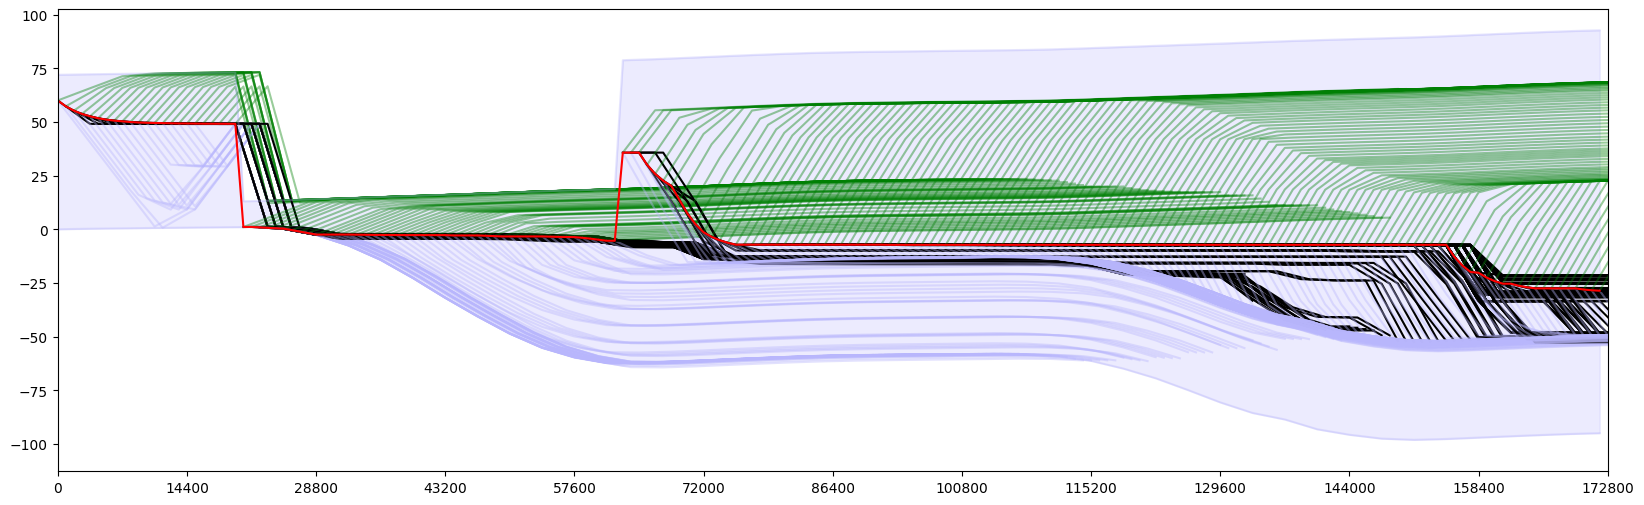

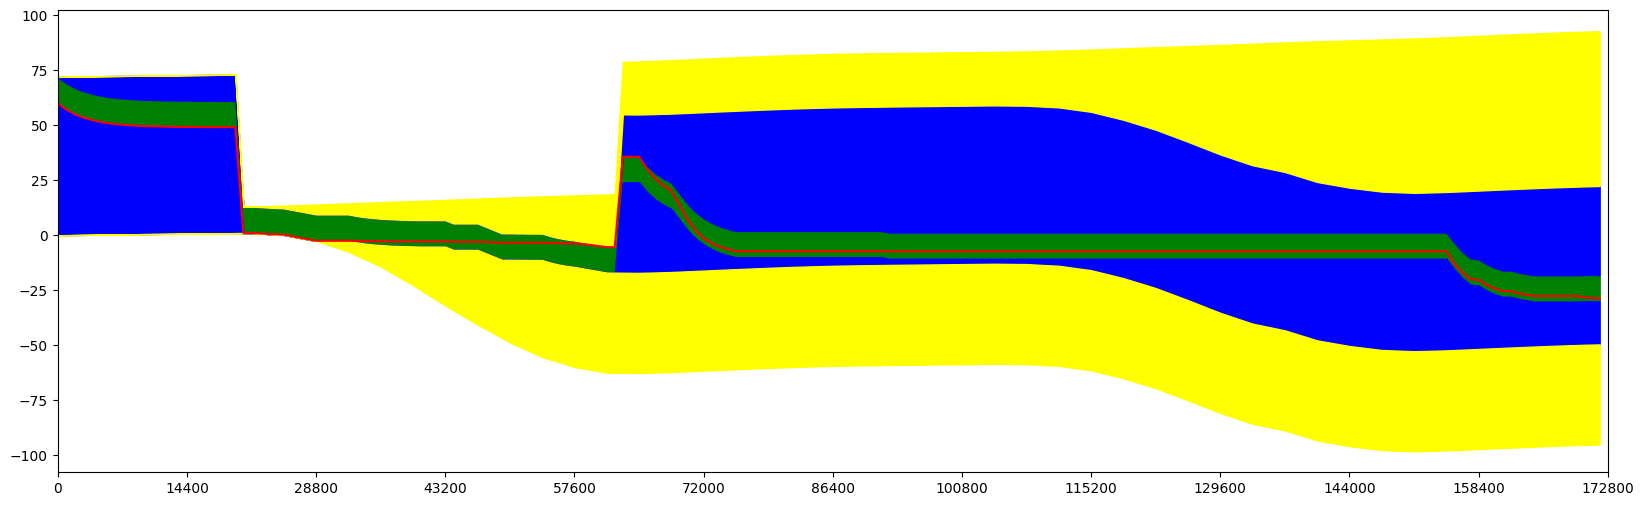

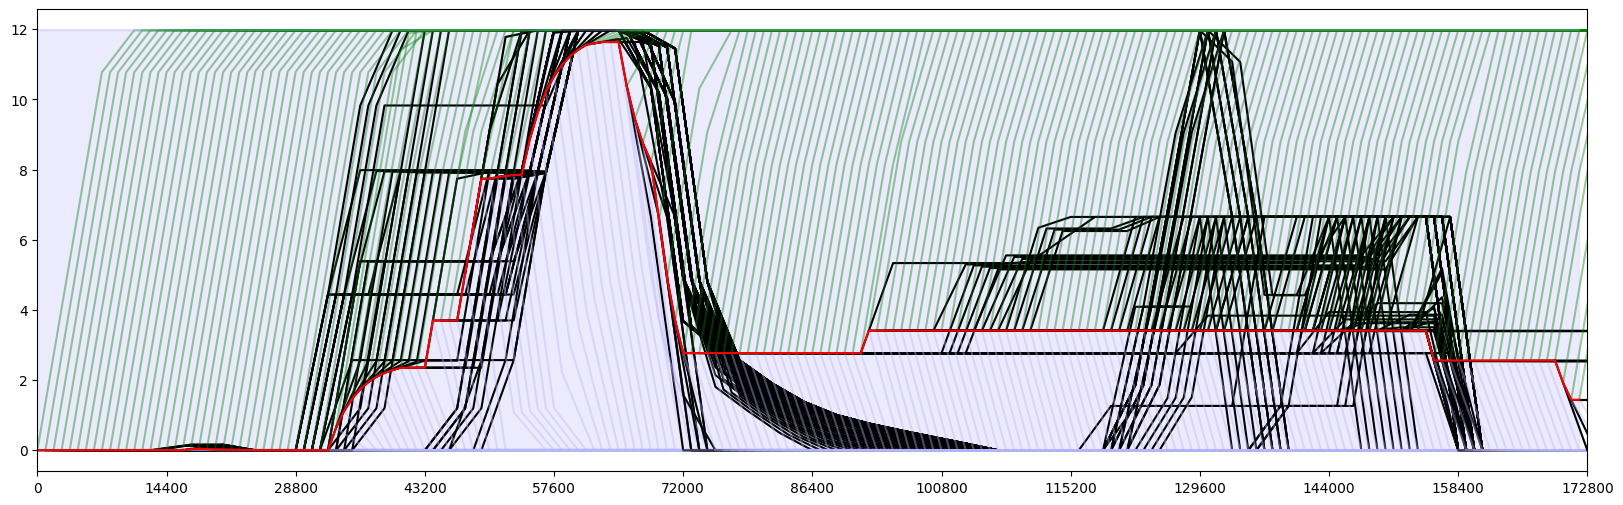

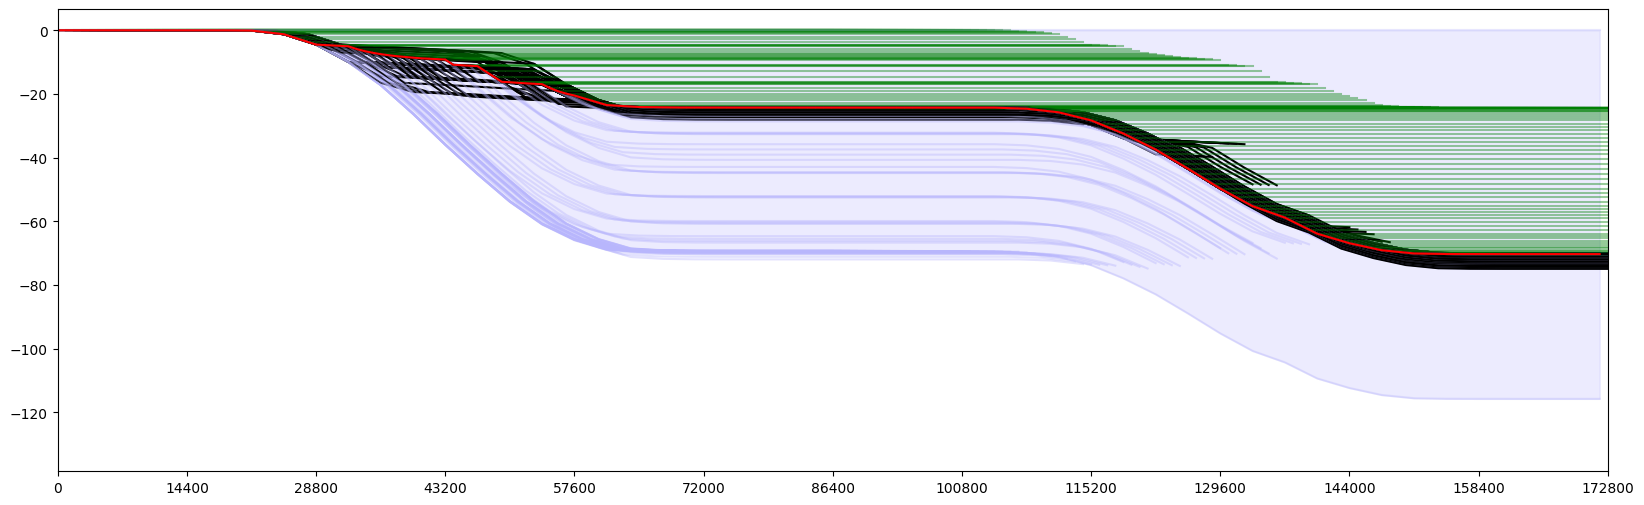

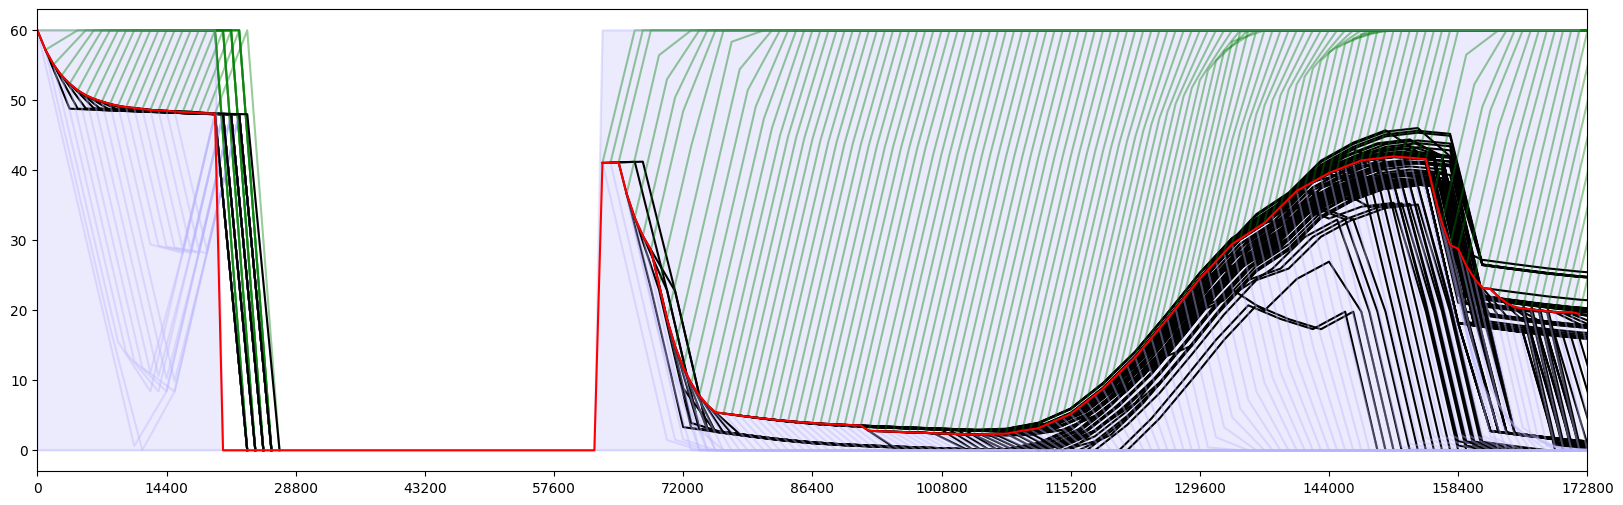

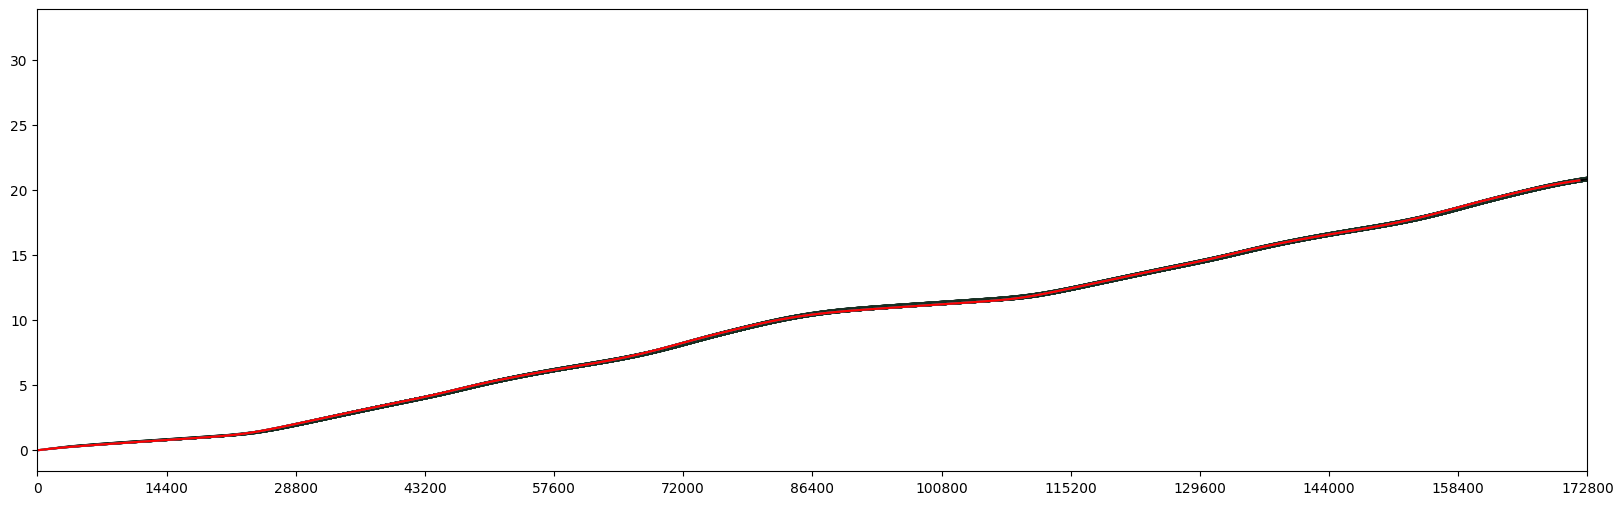

In [36]:
# PLOTTING
# prices
#plot_prices(prices)

# summed
plot_trajectories(traj_full_sum, traj_real_sum)
plot_stacked(traj_real_stacked, 4)

# single
plot_trajectories(traj_full[traj_full.asset_uuid == bat], traj_real[traj_real.asset_uuid == bat])
plot_trajectories(traj_full[traj_full.asset_uuid == pv], traj_real[traj_real.asset_uuid == pv])
plot_trajectories(traj_full[traj_full.asset_uuid == evcs], traj_real[traj_real.asset_uuid == evcs])
plot_trajectories(traj_full[traj_full.asset_uuid == load], traj_real[traj_real.asset_uuid == load])


In [48]:
from pathlib import Path

# Output

def export():
    out_dir = "trajectories"
    Path(out_dir).mkdir(exist_ok=True)

    traj_real_sum_export = traj_real_sum.copy().astype({"current_tick": "float"})
    traj_real_sum_export.loc[:, "current_tick"] /= 3600
    traj_real_sum_export.to_csv(out_dir + "/traj_real_sum.csv", index=False)

    traj_real_stacked_export = traj_real_stacked.copy().astype({"current_tick": "float"})
    traj_real_stacked_export.loc[:, "current_tick"] /= 3600
    traj_real_stacked_export.to_csv(out_dir + "/traj_real_stacked.csv", index=False)

    for curr_tick in traj_full_sum.current_tick.unique(): #[0, 900, 1800, 2700, 3600]:
        traj_full_sum_tick = traj_full_sum[traj_full_sum.current_tick == curr_tick].copy().astype({"current_tick": "float", "tick": "float"})
        traj_full_sum_tick.loc[:, ["current_tick", "tick"]] /= 3600

        file_name = "traj_full_sum_" + str(curr_tick) + ".csv"
        traj_full_sum_tick.to_csv(out_dir + "/" + file_name, columns=["tick", "state", "tight_e_min", "tight_e_max"], index=False)

export()